# Un grafo S7 simétrico, descrito con cuatro números

Este notebook es una variante de `Grafo_explicito_S7.ipynb`. Allá la plantilla S7 se optimiza sin
ninguna simetría y el redondeo a enteros cuida tres ecuaciones blandas con un reticulado. Acá se impone
desde el principio la **simetría de reflejo** de S7 y se la mantiene hasta el grafo. El objetivo no es el
grafo más chico, sino uno **sencillo de describir y de entender**.

El camino:

1. **La simetría** (sección 1): qué es el reflejo de S7 y por qué las cuatro densidades cruzadas no
   pueden ser todas iguales.
2. **Fase 0 simétrica** (sección 2): el SDP con la restricción de reflejo. No cuesta $\mu$ y deja solo
   cuatro densidades intermedias.
3. **Por qué la simetría ayuda al redondeo** (sección 3): de las tres direcciones blandas, dos son
   antisimétricas y desaparecen si los grados son simétricos.
4. **Fase 1 simétrica** (sección 4): cuatro enteros, una ecuación blanda, búsqueda exhaustiva.
5. **Certificado** (sección 5): el mismo de `Grafo_explicito_S7.ipynb`, sin cambios.
6. **El grafo** (secciones 6 y 7): su descripción completa y cómo se ve.
7. **Validación** (sección 8): el grafo real, armado desde la regla de adyacencia, y su espectro
   completo por bloques de Fourier, contra el certificado.

**Cómo está escrito.** Igual que el notebook original: primero la teoría, después el código y al final
los resultados. Las funciones nuevas están en este notebook; las que ya existen (evaluación exacta,
certificado, blow-up) se importan de `src/`. Todo corre acá, en CPU, en unos pocos minutos.

**Colab.** Este notebook usa `src/` y `data/` del repo, que es privado. En Colab, la celda de abajo lo clona usando un token de GitHub guardado en los Secrets (ícono de la llave, nombre `GITHUB_TOKEN`, con "Notebook access" activado); en local no hace nada. Para traer cambios nuevos: `!git -C /content/investighaton-teo-optimizacion-2026 pull`.

In [1]:
import os
import sys

EN_COLAB = "google.colab" in sys.modules
CARPETA_REPO = "/content/investighaton-teo-optimizacion-2026"

if EN_COLAB:
    if not os.path.exists(CARPETA_REPO):
        from google.colab import userdata
        token = userdata.get("GITHUB_TOKEN")
        !git clone -q https://{token}@github.com/Nicoyanz98/investighaton-teo-optimizacion-2026.git {CARPETA_REPO}
    %cd {CARPETA_REPO}/notebooks
    !pip install -q -r requirements.txt

**Imports y utilidades.** De `src/` se usan la evaluación exacta de datos enteros (`evaluar_enteros`), el
certificado del blow-up (`certificar_blowup`) y algunas funciones chicas; de `scripts/visualizar_grafo.py`,
la figura de la estructura. Para la sección 8, la clase `GrafoImplicito` (el grafo guardado como
vectores, sin la matriz) y los módulos `validacion` y `espectro`, contra los que se comparan las copias. `mostrar_tabla` es la misma del notebook original.

In [2]:
import itertools
import sys
import time
from pathlib import Path

sys.path.insert(0, "..")

import cvxpy as cp
import matplotlib
import matplotlib.pyplot as plt
import mpmath as mp
import numpy as np
from IPython.display import Image, display
from scipy.linalg import eigh_tridiagonal
from scipy.optimize import minimize

from src.blowup import certificar_blowup, descripcion_compacta
from src.enteros import evaluar_enteros, mu_entero, paso_grado, tamanos_enteros, tamanos_exactos
from src import espectro, validacion
from src.experimentos import cargar_json, guardar_json, silenciar_avisos
from src.plantillas import fuerzas
from src.s7 import esquina
from src.validacion import Arreglos, GrafoImplicito

silenciar_avisos()
mp.mp.dps = 50
plt.rcParams["figure.dpi"] = 110
COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
TINTA = "#1f2328"
BORDE = "#d0d7de"
FONDO_ENCABEZADO = "#e8ecf0"
FONDO_ALTERNO = "#f6f8fa"
FONDO_RESALTE = "#dbeafe"


def mostrar_tabla(columnas, filas, titulo=None, resaltar=()):
    # Dibuja una tabla de resultados con matplotlib: encabezado gris, filas alternadas y filas resaltadas.
    textos = []
    for fila in filas:
        textos.append([str(valor) for valor in fila])
    fig, eje = plt.subplots(figsize=(1, 0.22 * (len(filas) + 1)))
    eje.axis("off")
    tabla = eje.table(cellText=textos, colLabels=columnas, loc="center", cellLoc="center")
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(9)
    tabla.auto_set_column_width(list(range(len(columnas))))
    tabla.scale(1, 1.3)
    for (i, j), celda in tabla.get_celld().items():
        celda.set_edgecolor(BORDE)
        celda.set_linewidth(0.6)
        celda.PAD = 0.15
        celda.get_text().set_color(TINTA)
        if i == 0:
            celda.set_facecolor(FONDO_ENCABEZADO)
            celda.get_text().set_fontweight("bold")
        elif i - 1 in resaltar:
            celda.set_facecolor(FONDO_RESALTE)
            celda.get_text().set_fontweight("bold")
        elif i % 2 == 0:
            celda.set_facecolor(FONDO_ALTERNO)
    if titulo:
        # el título va arriba a la izquierda de la tabla (no de los ejes, que son más chicos)
        fig.canvas.draw()
        caja = tabla.get_window_extent(fig.canvas.get_renderer())
        x0, y1 = eje.transAxes.inverted().transform((caja.x0, caja.y1))
        eje.annotate(titulo, xy=(x0, y1), xycoords="axes fraction", xytext=(0, 5), textcoords="offset points",
                     fontsize=10, color=TINTA)
    plt.show()


def si_no(valor):
    # Texto para un booleano en las tablas.
    return "sí" if valor else "no"

## 1. La simetría de S7

**El reflejo.** S7 tiene A en $0$, B en $\pi/2$, C en $\pi$ y W en $3\pi/2$. La reflexión
$\varphi \mapsto \pi - \varphi$ (un espejo que pasa por B y por W) deja la figura igual si cada cluster va
al lugar de otro:
- Am está en $-h$ y va a $\pi + h$, que es donde está **Cp**; y Ap va a **Cm**;
- Bm ($\pi/2 - wh$) va a $\pi/2 + wh$, que es **Bp**;
- W ($3\pi/2$) va a $-\pi/2$, que es el mismo punto: W queda fijo.

Para que el estado sea simétrico, los desplazamientos tienen que cumplir $s_{Cp} = -s_{Am}$,
$s_{Cm} = -s_{Ap}$, $s_{Bp} = -s_{Bm}$. Quedan **3 desplazamientos libres** en lugar de 6. Las densidades
también tienen que respetar el espejo: $P_{ab} = P_{R(a)R(b)}$, donde $R$ es el reflejo.

**Por qué no son iguales las cuatro densidades cruzadas.** En el patrón límite (Tabla II de O'Keeffe) los
cuatro pares cruzados valen $q$. Con $h > 0$ no son geométricamente iguales. Por ejemplo, Bp está corrido
hacia C ($\pi/2 + wh$):
- **Am** queda a $\pi/2 + (1+w)h$ de Bp, a **más** de 90°: un par **lejano**;
- **Cm** queda a $\pi/2 - (1+w)h$ de Bp, a **menos** de 90°: un par **cercano**.

El peso de un par en la estabilidad de los modos de cluster es $\cos(\varphi_a - \varphi_b)$: negativo en
los pares lejanos (sus links desestabilizan) y positivo en los cercanos (estabilizan). El reflejo empareja
lejano con lejano (Am–Bp con Cp–Bm) y cercano con cercano (Ap–Bm con Cm–Bp), así que la simetría permite
dos valores distintos de $q$, uno por tipo.

**El código.** Fases de S7, desplazamientos simétricos a partir de 3 parámetros y una tabla que muestra
los ángulos de los cuatro pares cruzados, con los desplazamientos de O'Keeffe.

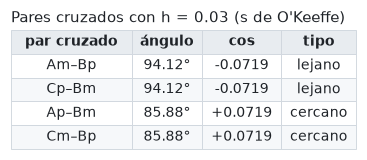

In [3]:
NOMBRES = ["Am", "Ap", "Bm", "Bp", "Cm", "Cp", "W"]
SECTORES = [0, 0, 1, 1, 2, 2, 3]
REFLEJO = [5, 4, 3, 2, 1, 0, 6]          # Am↔Cp, Ap↔Cm, Bm↔Bp, W fijo
K_S7 = [3] * 6 + [5]                     # tamaños (3, 5): x = (3, …, 3, 5)/23
H = 0.03
MARGEN = 1e-3


def fases_s7(h, s):
    # φ = fase del sector (múltiplo de π/2) + h·s; W queda en 3π/2.
    desplazamientos = np.concatenate([s, [0.0]])
    return np.array(SECTORES) * np.pi / 2 + h * desplazamientos


def s_simetrico(p):
    # Desplazamientos (s_Am, s_Ap, s_Bm) → los seis, con s_Cp = −s_Am, s_Cm = −s_Ap, s_Bp = −s_Bm.
    am, ap, bm = p
    return np.array([am, ap, bm, -bm, -ap, -am])


_, w_estrella, _ = esquina(30)
w_estrella = float(w_estrella)
phi_okeeffe = fases_s7(H, s_simetrico([-1.0, 1.0, -w_estrella]))
assert np.allclose(np.cos(phi_okeeffe[REFLEJO]), np.cos(np.pi - phi_okeeffe))   # el estado es simétrico

filas = []
for a, b, tipo in [(0, 3, "lejano"), (5, 2, "lejano"), (1, 2, "cercano"), (4, 3, "cercano")]:
    angulo = abs(phi_okeeffe[a] - phi_okeeffe[b])
    filas.append([f"{NOMBRES[a]}–{NOMBRES[b]}", f"{np.degrees(angulo):.2f}°", f"{np.cos(angulo):+.4f}", tipo])
mostrar_tabla(["par cruzado", "ángulo", "cos", "tipo"], filas, titulo=f"Pares cruzados con h = {H} (s de O'Keeffe)")

Los pares de cada tipo están a exactamente el mismo ángulo, con coseno del mismo signo: el reflejo los
intercambia. Entre tipos, el signo del coseno es opuesto.

## 2. Fase 0 simétrica

**El SDP es el mismo** del notebook original (sección 3 de allá): con $x$ y $\varphi$ fijos se maximiza
$\mu = \min_a \sum_b P_{ab}x_b$ sobre las densidades, con equilibrio $F = 0$, $c \ge 10^{-3}$ y
$Q^\top L Q / h^2 \succeq \varepsilon I$. Se le pueden agregar restricciones **lineales** en $P$ sin que
deje de ser un SDP:
- `"reflejo"`: $P = R P R^\top$, y los desplazamientos simétricos (Nelder–Mead en 3 parámetros);
- `"q_unico"`: los cuatro pares cruzados con la misma densidad (la Tabla II con un solo $q$);
- `"vecinos_en_1"`: los pares vecinos que valen 1 en el patrón límite quedan en 1 (solo se mueven los
  cuatro cruzados).

**Por qué el reflejo no cuesta $\mu$.** Si $\varphi$ es simétrico, el problema es invariante por el
reflejo: si $P$ es factible, $RPR^\top$ también, con el mismo $\mu$. Como el problema es convexo, el
promedio $\tfrac12(P + RPR^\top)$ también es factible y tiene al menos el mismo $\mu$. Entonces siempre
hay un óptimo simétrico, y pedir simetría no pierde nada. En cambio, Nelder–Mead busca en 3 parámetros en
lugar de 6, que es más fácil.

**El código.** `sdp_s7` es el `sdp_interno` del notebook original con las restricciones opcionales;
`optimizar_s7` hace Nelder–Mead en los desplazamientos (6, o 3 con reflejo) desde el ansatz de O'Keeffe.

In [4]:
def prohibidos_s7():
    # Pares sin links: sectores opuestos (A–C y B–W).
    prohibidos = np.zeros((7, 7))
    for a in range(7):
        for b in range(7):
            if abs(SECTORES[a] - SECTORES[b]) == 2:
                prohibidos[a, b] = 1
    return prohibidos


CRUZADOS = [(0, 3), (1, 2), (2, 5), (3, 4)]                                 # Am–Bp, Ap–Bm, Bm–Cp, Bp–Cm
VECINOS_EN_1 = [(0, 2), (1, 3), (2, 4), (3, 5), (0, 6), (1, 6), (4, 6), (5, 6)]


def sdp_s7(x, phi, h, margen, restricciones=()):
    # Mayor μ sobre las densidades P con x y φ fijos. Devuelve (μ, P) o (None, None) si es infactible.
    m = len(x)
    diferencias = phi[:, None] - phi[None, :]
    senos = np.sin(diferencias)
    cosenos = np.cos(diferencias)
    pesos_L = np.outer(x, x) * cosenos
    np.fill_diagonal(pesos_L, 0)

    P = cp.Variable((m, m), symmetric=True)
    t = cp.Variable()
    K = cp.multiply(P, pesos_L)
    L = cp.diag(cp.sum(K, axis=1)) - K
    Q, _ = np.linalg.qr(np.eye(m) - 1.0 / m)
    Q = Q[:, : m - 1]
    lista = [
        P >= 0,
        P <= 1,
        cp.diag(P) == 1,
        P @ x >= t,
        cp.multiply(P, senos) @ x == 0,
        cp.multiply(P, cosenos) @ x >= 1e-3,
        (Q.T @ L @ Q) / h**2 >> margen * np.eye(m - 1),
        cp.multiply(P, prohibidos_s7()) == 0,
    ]
    if "reflejo" in restricciones:
        R = np.eye(m)[REFLEJO]
        lista.append(P == R @ P @ R.T)
    if "q_unico" in restricciones:
        a0, b0 = CRUZADOS[0]
        for a, b in CRUZADOS[1:]:
            lista.append(P[a, b] == P[a0, b0])
    if "vecinos_en_1" in restricciones:
        for a, b in VECINOS_EN_1:
            lista.append(P[a, b] == 1)
    problema = cp.Problem(cp.Maximize(t), lista)
    try:
        problema.solve(solver="CLARABEL")
    except cp.error.SolverError:
        return None, None
    if problema.status not in ("optimal", "optimal_inaccurate"):
        return None, None
    return float(t.value), np.array(P.value)


def optimizar_s7(x, h, margen, restricciones=()):
    # Nelder–Mead en los desplazamientos (3 con reflejo, 6 sin). Devuelve (μ, s, P) o (None, s, None).
    simetrico = "reflejo" in restricciones
    p0 = np.array([-1.0, 1.0, -w_estrella]) if simetrico else np.array([-1.0, 1.0, -w_estrella, w_estrella, -1.0, 1.0])

    def desplazamientos(p):
        return s_simetrico(p) if simetrico else p

    def objetivo(p):
        mu, _ = sdp_s7(x, fases_s7(h, desplazamientos(p)), h, margen, restricciones)
        return 1.0 if mu is None else -mu

    resultado = minimize(objetivo, p0, method="Nelder-Mead", options={"maxiter": 600, "xatol": 1e-5, "fatol": 1e-9})
    s = desplazamientos(resultado.x)
    mu, P = sdp_s7(x, fases_s7(h, s), h, margen, restricciones)
    return mu, s, P

Corremos las cuatro variantes con $h = 0.03$, $\varepsilon = 10^{-3}$ y tamaños $(3, 5)$, la misma
plantilla que usa el notebook original. Tarda alrededor de un minuto y medio.

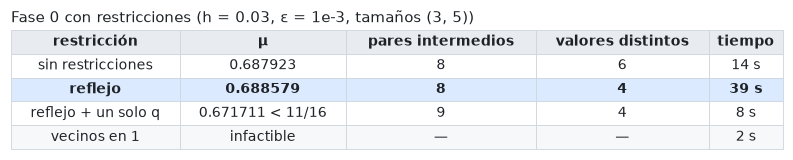

In [5]:
x_s7 = np.array(K_S7) / sum(K_S7)
variantes = {}
filas = []
for nombre, restricciones in [("sin restricciones", ()), ("reflejo", ("reflejo",)),
                              ("reflejo + un solo q", ("reflejo", "q_unico")),
                              ("vecinos en 1", ("vecinos_en_1",))]:
    inicio = time.time()
    mu, s, P = optimizar_s7(x_s7, H, MARGEN, restricciones)
    variantes[nombre] = (mu, s, P)
    if mu is None:
        filas.append([nombre, "infactible", "—", "—", f"{time.time() - inicio:.0f} s"])
        continue
    intermedios = [P[a, b] for a in range(7) for b in range(a + 1, 7) if 1e-6 < P[a, b] < 1 - 1e-6]
    distintos = len({round(v, 4) for v in intermedios})
    filas.append([nombre, f"{mu:.6f}" + (" < 11/16" if mu < 11 / 16 else ""), len(intermedios), distintos,
                  f"{time.time() - inicio:.0f} s"])
mostrar_tabla(["restricción", "μ", "pares intermedios", "valores distintos", "tiempo"], filas,
              titulo="Fase 0 con restricciones (h = 0.03, ε = 1e-3, tamaños (3, 5))", resaltar=[1])

**Lectura.**
- **Reflejo:** da el $\mu$ más alto. No pierde nada, como predice el argumento de convexidad, y además
  gana un poco, porque Nelder–Mead encuentra mejor el óptimo en 3 parámetros que en 6 (sin restricciones
  queda en 0.68792, algo por debajo incluso de la plantilla del notebook original, 0.6885). Los pares
  intermedios son los mismos 8, pero con **4 valores distintos en lugar de 6**.
- **Un solo $q$:** queda por debajo de $11/16$. Forzar lejano = cercano cuesta del orden de $h$ en $\mu$,
  y eso es justo la ventaja que tiene S7 sobre $11/16$.
- **Vecinos en 1:** es infactible. Con $h > 0$ algunos pares que en el patrón límite valen 1 tienen que
  bajar. Es lo mismo que hace O'Keeffe con su corrección $p'$ (Apéndice A: elige $\kappa$ para que
  $p' < 0$ en todos los pares vecinos con $p = 1$).

**La plantilla simétrica.** La matriz $P$ completa. Las densidades que no son 0 ni 1 están pintadas, con
un color por pareja espejo.

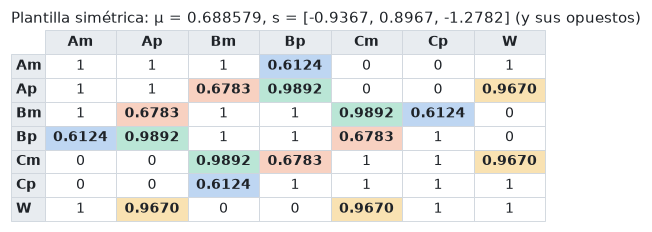

Am–Bp y Bm–Cp: 0.6124
Ap–Bm y Bp–Cm: 0.6783
Ap–Bp y Bm–Cm: 0.9892
Ap–W y Cm–W: 0.9670


In [6]:
def mostrar_matriz(P, colores_celda, titulo):
    # Matriz de densidades 7 × 7 con nombres de clusters; las celdas con color son las intermedias.
    textos = []
    for fila in P:
        textos.append(["1" if v > 1 - 1e-6 else "0" if v < 1e-6 else f"{v:.4f}" for v in fila])
    fig, eje = plt.subplots(figsize=(1, 0.22 * (len(P) + 1)))
    eje.axis("off")
    tabla = eje.table(cellText=textos, rowLabels=NOMBRES, colLabels=NOMBRES, loc="center", cellLoc="center")
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(9)
    tabla.auto_set_column_width(list(range(-1, len(P))))
    tabla.scale(1, 1.3)
    for (i, j), celda in tabla.get_celld().items():
        celda.set_edgecolor(BORDE)
        celda.set_linewidth(0.6)
        celda.PAD = 0.15
        celda.get_text().set_color(TINTA)
        if i == 0 or j == -1:
            celda.set_facecolor(FONDO_ENCABEZADO)
            celda.get_text().set_fontweight("bold")
        elif colores_celda[i - 1][j] is not None:
            celda.set_facecolor(colores_celda[i - 1][j])
            celda.get_text().set_fontweight("bold")
    fig.canvas.draw()
    caja = tabla.get_window_extent(fig.canvas.get_renderer())
    x0, y1 = eje.transAxes.inverted().transform((caja.x0, caja.y1))
    eje.annotate(titulo, xy=(x0, y1), xycoords="axes fraction", xytext=(0, 5), textcoords="offset points",
                 fontsize=10, color=TINTA)
    plt.show()


mu_simetrica, s_plantilla, P_sdp = variantes["reflejo"]
colores_celda = [[None] * 7 for _ in range(7)]
leyenda = []
for a in range(7):
    for b in range(a + 1, 7):
        if 1e-6 < P_sdp[a, b] < 1 - 1e-6 and colores_celda[a][b] is None:
            ra, rb = REFLEJO[a], REFLEJO[b]
            color = matplotlib.colors.to_rgba(COLORES[len(leyenda)], 0.3)
            for i, j in [(a, b), (b, a), (ra, rb), (rb, ra)]:
                colores_celda[i][j] = color
            leyenda.append(f"{NOMBRES[a]}–{NOMBRES[b]} y {NOMBRES[min(ra, rb)]}–{NOMBRES[max(ra, rb)]}: {P_sdp[a, b]:.4f}")
mostrar_matriz(P_sdp, colores_celda,
               f"Plantilla simétrica: μ = {mu_simetrica:.6f}, s = {np.round(s_plantilla[:3], 4).tolist()} (y sus opuestos)")
for linea in leyenda:
    print(linea)

Son **cuatro valores**, cada uno en un par y su espejo (el mismo color); todas las demás densidades son 0
o 1, y la matriz es simétrica respecto del espejo: la fila de Am leída al revés es la de Cp, etc.
- **Azul y naranja:** los pares cruzados, el lejano más fino (Am–Bp, Bm–Cp) y el cercano más grueso
  (Ap–Bm, Bp–Cm).
- **Verde y amarillo:** pares que en el patrón límite valen 1 y bajan un poco: los de Ap con Bp y con W, y
  sus espejos, Cm con Bm y con W. Son los pares que O'Keeffe adelgaza más ($p' = -1.9$ y $-2.86$); los
  que él adelgaza poco, el SDP los deja en 1.

## 3. Por qué la simetría ayuda al redondeo

**El problema del redondeo** (sección 5 del notebook original). El Jacobiano $J$ del equilibrio tiene
valores singulares muy chicos: el equilibrio está al lado de un pliegue. En cada dirección blanda $k$, el
equilibrio es raíz de $\sigma_k y + \tfrac{c_k}{2} y^2 + \rho_k = 0$, así que el error $\rho_k$ que mete el
redondeo tiene que ser menor que $\sigma_k^2/(2|c_k|)$, o el equilibrio desaparece. Sin simetría hay 3
direcciones blandas.

**Simetría de las direcciones.** Un movimiento de las fases $\delta\varphi$ se refleja como
$\delta\varphi_{R(a)} \mapsto -\delta\varphi_a$ (el espejo invierte el sentido de giro). Cada vector
singular de $J$ es **simétrico** (no cambia al reflejarlo) o **antisimétrico** (cambia de signo), porque
$J$ conmuta con el reflejo cuando la plantilla es simétrica.

**Si los datos enteros también son simétricos**, el error de redondeo es simétrico: no puede empujar en
una dirección antisimétrica. Las ecuaciones antisimétricas se cumplen **solas** y el equilibrio se busca
solo entre los estados simétricos. En las direcciones antisimétricas ya no hay pliegue que cuidar: el
redondeo solo cambia las densidades en $\sim 1/n$, y alcanza con que ese cambio sea menor que el margen de
estabilidad (los autovalores de $L$, de orden $5\cdot10^{-6}$). Es una condición lineal en $1/n$, no
cuadrática como la del pliegue.

**El código.** Jacobiano completo de $F$ respecto de las 7 fases, su SVD y la paridad de cada vector
singular $v$, medida como $v^\top R v$ ($+1$ simétrico, $-1$ antisimétrico).

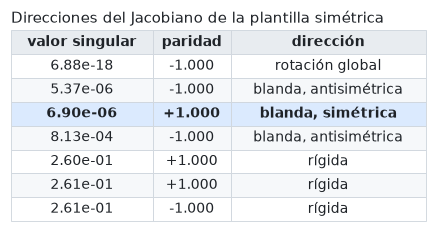

In [7]:
def jacobiano_completo(x, phi, P):
    # ∂F_a/∂φ_b para las 7 fases (incluye la rotación global, que tiene valor singular 0).
    J = np.zeros((7, 7))
    for a in range(7):
        for b in range(7):
            if a != b:
                J[a, b] = -P[a, b] * x[b] * np.cos(phi[a] - phi[b])
        J[a, a] = -J[a].sum()
    return J


def matriz_reflejo():
    # δφ ↦ R δφ con (R δφ)_{R(a)} = −δφ_a.
    R = np.zeros((7, 7))
    for a in range(7):
        R[REFLEJO[a], a] = -1
    return R


phi_plantilla = fases_s7(H, s_plantilla)
J_completo = jacobiano_completo(x_s7, phi_plantilla, P_sdp)
_, singulares, Vt = np.linalg.svd(J_completo)
R_fases = matriz_reflejo()
filas = []
for i in np.argsort(singulares):
    paridad = Vt[i] @ R_fases @ Vt[i]
    if singulares[i] < 1e-12:
        tipo = "rotación global"
    elif singulares[i] < 1e-2:
        tipo = "blanda, " + ("simétrica" if paridad > 0 else "antisimétrica")
    else:
        tipo = "rígida"
    filas.append([f"{singulares[i]:.2e}", f"{paridad:+.3f}", tipo])
mostrar_tabla(["valor singular", "paridad", "dirección"], filas, titulo="Direcciones del Jacobiano de la plantilla simétrica",
              resaltar=[i for i, f in enumerate(filas) if "simétrica" in f[2] and "anti" not in f[2]])

De las tres direcciones blandas, **dos son antisimétricas** y **una es simétrica** (resaltada). Con
datos enteros simétricos, solo esa hay que cuidar con el redondeo.

**El sistema reducido.** Un estado simétrico queda determinado por $\psi = (\varphi_{Am}, \varphi_{Ap},
\varphi_{Bm})$: las demás fases son $\pi - \psi$ de su espejo, y W queda en $3\pi/2$. Las ecuaciones
también se reducen: $F_{R(a)} = -F_a$ en un estado simétrico, y $F_W = 0$ sola. Quedan **3 ecuaciones
($F_{Am}, F_{Ap}, F_{Bm}$) con 3 incógnitas**, y su Jacobiano tiene 2 valores singulares grandes y 1 chico.
Ya no hay rotación global: un estado simétrico rotado deja de ser simétrico.

## 4. Fase 1 simétrica: cuatro enteros, una ecuación

**Datos enteros simétricos.** Tamaños $n_a = k_a g$ ($n = 23g$) y grados $d_{ab}$, con
$n_a d_{ab} = n_b d_{ba}$ y $d_{aa} = n_a - 1$, igual que en el notebook original. Los pares en 0 o en 1
quedan fijos (vacío o completo). Los 8 pares intermedios forman 4 parejas espejo, y en cada pareja se usa
**el mismo grado**. Son **4 enteros** $j_1, \dots, j_4$, con $d_{ab} = j_c \cdot \text{paso}$, donde el paso
es el que pide $n_a d_{ab} = n_b d_{ba}$ (1 entre mitades, 5 entre una mitad y W).

**Antes de redondear: pulir.** El SDP deja $F \approx 10^{-9}$. Como en el original, se corrige $P$ con el
cambio de menor norma que hace $F = 0$ exacto (F es lineal en $P$), pero acá con una variable por pareja
espejo, para que la plantilla pulida siga siendo simétrica: 3 ecuaciones, 4 incógnitas.

**El residuo blando.** Es la misma reducción de Lyapunov–Schmidt del original, en el sistema reducido:
1. SVD del Jacobiano reducido $J = U S V^\top$ en la plantilla: 2 direcciones rígidas y 1 blanda.
2. Para unos grados dados, Newton mueve $\psi$ solo en las 2 direcciones rígidas hasta que las 2 ecuaciones
   rígidas dan 0 (ahí Newton converge sin problemas).
3. Lo que queda en la dirección blanda es el residuo $g$: **un solo número**. El objetivo es elegir
   $j_1, \dots, j_4$ para que $|g|$ quede por debajo del umbral del pliegue, $\sigma^2/(2|c|)$.

El coeficiente $c$ de la forma normal se mide por diferencias finitas: es la derivada segunda de la
ecuación blanda a lo largo de la dirección blanda. (Las direcciones rígidas no lo modifican a segundo
orden, porque la ecuación blanda no ve los movimientos rígidos: $u_b^\top J V_r = 0$.)

**Newton entero por búsqueda exhaustiva.** Cerca de los grados ingenuos, $g$ es casi lineal en los
enteros:
$$g(j + u) \approx g(j) + G \cdot u, \qquad G_c = g(j + e_c) - g(j)$$
($G_c$ es cuánto cambia $g$ al sumarle 1 al entero $c$). Con 4 enteros y radio 20 hay
$41^4 \approx 2.8\cdot10^6$ vectores $u$ posibles, y evaluar $g + G\cdot u$ en todos es una sola
multiplicación de matrices. Se elige el $u$ con menor $|g + G\cdot u|$. Como el modelo lineal no es exacto,
se repite una vez más con radio 3 desde el nuevo punto. **No hace falta el reticulado**: con 1 ecuación y
4 incógnitas, buscar entre todos es instantáneo, y da el óptimo exacto del modelo lineal.

**El código.** Primero la simetrización y el pulido, después el sistema reducido y el residuo blando, y al
final los enteros.

In [8]:
def simetrizar(P, tolerancia=1e-6):
    # Promedio exacto con el reflejo, y los extremos que el SDP dejó a menos de tolerancia, a 0 o 1.
    R = np.eye(7)[REFLEJO]
    P = (P + R @ P @ R.T) / 2
    P = (P + P.T) / 2
    P[P < tolerancia] = 0
    P[P > 1 - tolerancia] = 1
    return P


def parejas_libres(P):
    # Pares intermedios agrupados por el reflejo: [[par, espejo], ...], con a < b en cada par.
    parejas = []
    vistos = set()
    for a in range(7):
        for b in range(a + 1, 7):
            if 0 < P[a][b] < 1 and (a, b) not in vistos:
                espejo = tuple(sorted((REFLEJO[a], REFLEJO[b])))
                parejas.append([(a, b), espejo])
                vistos |= {(a, b), espejo}
    return parejas


def fases_reducidas(psi):
    # Estado simétrico a partir de ψ = (φ_Am, φ_Ap, φ_Bm): φ_R(a) = π − φ_a y W en 3π/2.
    return [psi[0], psi[1], psi[2], mp.pi - psi[2], mp.pi - psi[1], mp.pi - psi[0], 3 * mp.pi / 2]


def ecuaciones_reducidas(x, psi, P):
    # (F_Am, F_Ap, F_Bm): en un estado simétrico las demás son sus opuestas y F_W = 0.
    F = fuerzas(x, fases_reducidas(psi), P, mp)
    return mp.matrix([F[0], F[1], F[2]])


def jacobiano_reducido(x, psi, P):
    # ∂(F_Am, F_Ap, F_Bm)/∂ψ por la regla de la cadena: dφ/dψ vale +1 en Am, Ap, Bm y −1 en sus espejos.
    phi = fases_reducidas(psi)
    dphi = [[1, 0, 0], [0, 1, 0], [0, 0, 1], [0, 0, -1], [0, -1, 0], [-1, 0, 0], [0, 0, 0]]
    J = mp.matrix(3, 3)
    for i, a in enumerate([0, 1, 2]):
        fila = [mp.mpf(0)] * 7                       # ∂F_a/∂φ_b
        for b in range(7):
            if b != a:
                termino = P[a][b] * x[b] * mp.cos(phi[a] - phi[b])
                fila[a] += termino
                fila[b] -= termino
        for j in range(3):
            J[i, j] = sum(fila[b] * dphi[b][j] for b in range(7))
    return J


def pulir_simetrico(x, psi, P, parejas):
    # Cambio de mínima norma en P, una variable por pareja espejo, con F(φ(ψ)) = 0 exacto.
    P = [[mp.mpf(float(v)) for v in fila] for fila in P]
    F = ecuaciones_reducidas(x, psi, P)
    phi = fases_reducidas(psi)
    A = mp.matrix(3, len(parejas))
    for c, pareja in enumerate(parejas):
        E = [[mp.mpf(0)] * 7 for _ in range(7)]       # F es lineal en P: la columna c es F(E_c)
        for a, b in pareja:
            E[a][b] = E[b][a] = mp.mpf(1)
        columna = fuerzas(x, phi, E, mp)
        for i in range(3):
            A[i, c] = columna[i]
    delta = A.T * mp.lu_solve(A * A.T, -F)
    for c, pareja in enumerate(parejas):
        for a, b in pareja:
            P[a][b] += delta[c]
            P[b][a] = P[a][b]
    return P


P_simetrica = simetrizar(P_sdp)
parejas = parejas_libres(P_simetrica)
x_exacto = [mp.mpf(v.numerator) / v.denominator for v in tamanos_exactos(K_S7)]
psi_plantilla = [mp.mpf(H) * mp.mpf(float(s_plantilla[0])), mp.mpf(H) * mp.mpf(float(s_plantilla[1])),
                 mp.pi / 2 + mp.mpf(H) * mp.mpf(float(s_plantilla[2]))]
P_pulida = pulir_simetrico(x_exacto, psi_plantilla, P_simetrica, parejas)
F_pulida = fuerzas(x_exacto, fases_reducidas(psi_plantilla), P_pulida, mp)
cambio = max(abs(float(P_pulida[a][b]) - P_sdp[a, b]) for a in range(7) for b in range(7))
print(f"parejas libres: {[[NOMBRES[a] + '–' + NOMBRES[b] for a, b in p] for p in parejas]}")
print(f"max |F| después de pulir: {mp.nstr(max(abs(v) for v in F_pulida), 3)};  cambio máximo en P: {cambio:.1e}")

parejas libres: [['Am–Bp', 'Bm–Cp'], ['Ap–Bm', 'Bp–Cm'], ['Ap–Bp', 'Bm–Cm'], ['Ap–W', 'Cm–W']]
max |F| después de pulir: 5.01e-52;  cambio máximo en P: 1.6e-08


**Grados, residuo blando y Newton entero.**

In [9]:
def grados_simetricos(P, parejas, j, g):
    # d a partir de un entero por pareja (d_ab = j_c · paso, igual en el par y en su espejo).
    n_a = tamanos_enteros(K_S7, g)
    d = [[0] * 7 for _ in range(7)]
    for a in range(7):
        d[a][a] = n_a[a] - 1
        for b in range(7):
            if b != a and P[a][b] == 1:
                d[a][b] = n_a[b]
    for c, pareja in enumerate(parejas):
        for a, b in pareja:
            d[a][b] = j[c] * paso_grado(K_S7, a, b)
            d[b][a] = d[a][b] * n_a[a] // n_a[b]
    return d


def enteros_ingenuos(P, parejas, g):
    # El múltiplo permitido más cercano a P_ab·n_b, para el primer par de cada pareja.
    n_a = tamanos_enteros(K_S7, g)
    j = []
    for pareja in parejas:
        a, b = pareja[0]
        j.append(int(mp.nint(P[a][b] * n_a[b] / paso_grado(K_S7, a, b))))
    return j


def densidades(d, g):
    # P_ab = d_ab/n_b en mpmath.
    n_a = tamanos_enteros(K_S7, g)
    return [[mp.mpf(d[a][b]) / n_a[b] for b in range(7)] for a in range(7)]


def base_blanda(x, psi, P):
    # SVD del Jacobiano reducido: (U_rígido, U_blando, V_rígido) y los valores singulares.
    J = np.array(jacobiano_reducido(x, psi, P).tolist(), dtype=float)
    U, singulares, Vt = np.linalg.svd(J)
    return (mp.matrix(U[:, :2].tolist()), mp.matrix(U[:, 2:].tolist()), mp.matrix(Vt[:2].T.tolist())), singulares


def residuo_blando(x, P, psi_referencia, base, iteraciones=30):
    # Newton en las 2 direcciones rígidas; devuelve el residuo de la blanda (un número) y ψ.
    U_r, U_b, V_r = base
    z = mp.matrix(2, 1)
    for _ in range(iteraciones):
        psi = [psi_referencia[i] + V_r[i, 0] * z[0] + V_r[i, 1] * z[1] for i in range(3)]
        rigidas = U_r.T * ecuaciones_reducidas(x, psi, P)
        if mp.norm(rigidas) < mp.mpf(10) ** (-mp.mp.dps + 10):
            break
        z = z - mp.lu_solve(U_r.T * jacobiano_reducido(x, psi, P) * V_r, rigidas)
    psi = [psi_referencia[i] + V_r[i, 0] * z[0] + V_r[i, 1] * z[1] for i in range(3)]
    return (U_b.T * ecuaciones_reducidas(x, psi, P))[0], psi


def newton_entero(x, P, parejas, psi_referencia, base, g, radios=(20, 3)):
    # Arranca del redondeo ingenuo; en cada paso elige, entre todos los u con |u_c| ≤ radio, el que
    # minimiza |g + G·u| en el modelo lineal. Devuelve los enteros, los grados, ψ y |g| en cada paso.
    j = enteros_ingenuos(P, parejas, g)
    historia = []
    for radio in radios:
        g_actual, _ = residuo_blando(x, densidades(grados_simetricos(P, parejas, j, g), g), psi_referencia, base)
        G = []
        for c in range(len(parejas)):
            j_mas = list(j)
            j_mas[c] += 1
            g_mas, _ = residuo_blando(x, densidades(grados_simetricos(P, parejas, j_mas, g), g), psi_referencia, base)
            G.append(float(g_mas - g_actual))
        historia.append(abs(float(g_actual)))
        candidatos = np.array(list(itertools.product(range(-radio, radio + 1), repeat=len(parejas))))
        u = candidatos[np.argmin(np.abs(float(g_actual) + candidatos @ np.array(G)))]
        j = [int(jc + uc) for jc, uc in zip(j, u)]
    d = grados_simetricos(P, parejas, j, g)
    g_final, psi = residuo_blando(x, densidades(d, g), psi_referencia, base)
    historia.append(abs(float(g_final)))
    return j, d, psi, historia


def forma_normal(x, psi, P):
    # (σ, c) de la ecuación blanda σ y + (c/2) y² a lo largo de la dirección blanda (diferencias finitas).
    U, _, Vt = np.linalg.svd(np.array(jacobiano_reducido(x, psi, P).tolist(), dtype=float))
    u_b = mp.matrix(U[:, 2].tolist())
    v_b = Vt[2]

    def blanda(y):
        return (u_b.T * ecuaciones_reducidas(x, [psi[i] + y * v_b[i] for i in range(3)], P))[0]

    e = mp.mpf("1e-8")
    sigma = (blanda(e) - blanda(-e)) / (2 * e)
    c = (blanda(e) - 2 * blanda(0) + blanda(-e)) / e**2
    return abs(float(sigma)), float(c)


base, singulares_reducidos = base_blanda(x_exacto, psi_plantilla, P_pulida)
sigma_blanda, c_blanda = forma_normal(x_exacto, psi_plantilla, P_pulida)
umbral = sigma_blanda**2 / (2 * abs(c_blanda))
print(f"valores singulares del Jacobiano reducido: {np.array2string(singulares_reducidos, precision=3)}")
print(f"forma normal: σ = {sigma_blanda:.3e}, c = {c_blanda:.2e}")
print(f"umbral del pliegue: σ²/(2|c|) = {umbral:.1e}   (σ² = {sigma_blanda**2:.1e})")

valores singulares del Jacobiano reducido: [2.612e-01 2.605e-01 6.903e-06]
forma normal: σ = 6.903e-06, c = 8.97e-04
umbral del pliegue: σ²/(2|c|) = 2.7e-08   (σ² = 4.8e-11)


**El barrido en $n$.** Para cada $n$ de la grilla se prueba el redondeo ingenuo (simétrico) y el Newton
entero, y se evalúa cada uno en exacto con `evaluar_enteros` (el mismo criterio del notebook original:
equilibrio por Newton en alta precisión, $\lambda_{\min}(L) > 0$, $c > 0$ y fases a menos de $h/4$ de
las de la plantilla). Tarda alrededor de un minuto.

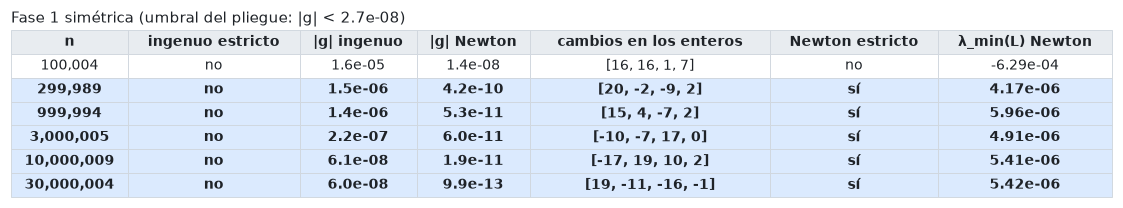

In [10]:
phi_referencia = [float(v) for v in fases_reducidas(psi_plantilla)]
barrido = []
for n_objetivo in [1e5, 3e5, 1e6, 3e6, 1e7, 3e7]:
    g = int(round(n_objetivo / sum(K_S7)))
    j_ingenuo = enteros_ingenuos(P_pulida, parejas, g)
    d_ingenuo = grados_simetricos(P_pulida, parejas, j_ingenuo, g)
    ingenuo = evaluar_enteros(K_S7, g, d_ingenuo, phi_referencia, H)
    j, d, psi, historia = newton_entero(x_exacto, P_pulida, parejas, psi_plantilla, base, g)
    phi = [float(v) for v in fases_reducidas(psi)]
    newton = evaluar_enteros(K_S7, g, d, phi, H, phi_referencia=phi_referencia)
    barrido.append({"g": g, "n": sum(K_S7) * g, "j": j, "j_ingenuo": j_ingenuo, "d": d, "historia": historia,
                    "ingenuo": ingenuo, "newton": newton})

filas = []
for r in barrido:
    cambios = [a - b for a, b in zip(r["j"], r["j_ingenuo"])]
    filas.append([f"{r['n']:,}", si_no(r["ingenuo"]["ok"]), f"{r['historia'][0]:.1e}", f"{r['historia'][-1]:.1e}",
                  str(cambios), si_no(r["newton"]["ok"]), f"{r['newton']['menor autovalor']:.2e}"])
mostrar_tabla(["n", "ingenuo estricto", "|g| ingenuo", "|g| Newton", "cambios en los enteros", "Newton estricto",
               "λ_min(L) Newton"], filas, titulo=f"Fase 1 simétrica (umbral del pliegue: |g| < {umbral:.1e})",
              resaltar=[i for i, r in enumerate(barrido) if r["newton"]["ok"]])

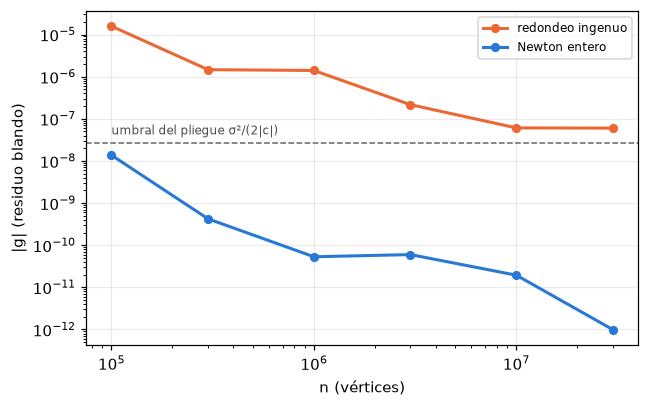

In [11]:
fig, eje = plt.subplots(figsize=(6, 3.8))
ns = [r["n"] for r in barrido]
eje.plot(ns, [r["historia"][0] for r in barrido], "o-", color=COLORES[1], lw=2, ms=5, label="redondeo ingenuo")
eje.plot(ns, [r["historia"][-1] for r in barrido], "o-", color=COLORES[0], lw=2, ms=5, label="Newton entero")
eje.axhline(umbral, color="0.4", lw=1, ls="--")
eje.text(ns[0], umbral * 1.6, "umbral del pliegue σ²/(2|c|)", color="0.3", fontsize=8)
eje.set(xscale="log", yscale="log", xlabel="n (vértices)", ylabel="|g| (residuo blando)")
eje.grid(alpha=0.25)
eje.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lectura.**
- **El umbral del pliegue** es $\sigma^2/(2|c|) \approx 2.7\cdot10^{-8}$, unas 500 veces más que
  $\sigma^2$, porque $c$ también es chico ($\sim 10^{-3}$, del orden de $h^2$).
- **El redondeo ingenuo** deja $|g|$ por encima del umbral en toda la grilla, así que nunca da un
  equilibrio estricto. $|g|$ baja como $1/n$ pero con saltos, porque depende de cuánto le toca redondear a
  cada entero.
- **El Newton entero** baja $|g|$ entre 3 y 5 órdenes de magnitud, cambiando cada entero en a lo sumo 20
  unidades (sobre grados de decenas de miles).
- **Desde $n = 3\cdot10^5$ el equilibrio es estricto** (el más chico de la grilla). Con $n = 10^5$ el
  residuo ya está debajo del umbral, pero $\lambda_{\min}(L)$ sale negativo: falla la otra condición. El
  redondeo cambia las densidades en $\sim 1/n = 10^{-5}$, más que el margen de estabilidad
  ($\sim 5\cdot10^{-6}$). Ahí está ahora el límite, y ya no en el pliegue.
- En el notebook original, el redondeo por reticulado de la misma familia necesitaba $n = 3\cdot10^7$.

## 5. El certificado

Es el mismo de la Fase 3 del notebook original (`src/blowup.py: certificar_blowup`), sin ningún cambio,
porque no usa la simetría:
- **cociente de $7\times7$:** Krawczyk (existe un único equilibrio en una caja de radio $10^{-40}$),
  $c > 0$ y Cholesky por intervalos de $L$ en toda la caja;
- **resto de los modos:** márgenes de Gershgorin positivos en los bloques de Fourier del blow-up;
- **$\mu = (\delta + 1)/n > 11/16$** en aritmética racional exacta.

Se certifican todos los grafos que la Fase 1 dio como estrictos.

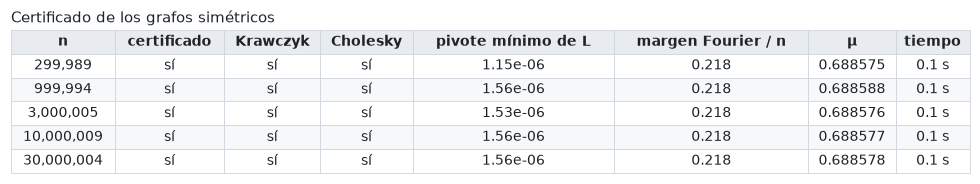

In [12]:
filas = []
for r in barrido:
    if not r["newton"]["ok"]:
        continue
    inicio = time.time()
    r["certificado"] = certificar_blowup(K_S7, r["g"], r["d"], r["newton"]["phi"], dps=100)
    c = r["certificado"]
    filas.append([f"{r['n']:,}", si_no(c["ok"]), si_no(c["krawczyk"]), si_no(c["cholesky"]),
                  f"{c['min pivote L (cota inf)']:.2e}", f"{c['margen fourier / n (cota inf)']:.3f}",
                  f"{c['mu']:.6f}", f"{time.time() - inicio:.1f} s"])
mostrar_tabla(["n", "certificado", "Krawczyk", "Cholesky", "pivote mínimo de L", "margen Fourier / n", "μ", "tiempo"],
              filas, titulo="Certificado de los grafos simétricos")

## 6. El grafo, completo

Tomamos el grafo certificado más chico de la grilla. Su descripción completa es:
- **tamaños:** $g$ y $k = (3, 3, 3, 3, 3, 3, 5)$, es decir seis mitades de $3g$ vértices y W de $5g$;
- **pares completos y vacíos:** los fijados por la plantilla;
- **cuatro enteros**, uno por pareja espejo.

Con eso, el blow-up circulante de la sección 7 del notebook original arma el grafo (en cada cluster, $k_a$
bloques de $\mathbb Z_g$ unidos por intervalos). Verificamos además que los grados son simétricos.

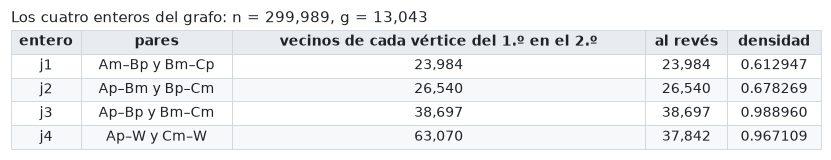

pares completos: Am–Ap, Am–Bm, Am–W, Bm–Bp, Bp–Cp, Cm–Cp, Cp–W
pares vacíos: A–C y B–W (sectores opuestos)
μ = 206565/299989 ≈ 0.688575  (11/16 = 0.6875)


In [13]:
grafo = min([r for r in barrido if r.get("certificado", {}).get("ok")], key=lambda r: r["n"])
d = grafo["d"]
n_a = tamanos_enteros(K_S7, grafo["g"])
for a in range(7):
    for b in range(7):
        assert d[REFLEJO[a]][REFLEJO[b]] == d[a][b]          # los grados respetan el espejo

filas = []
for c, pareja in enumerate(parejas):
    (a, b), (ra, rb) = pareja
    filas.append([f"j{c + 1}", f"{NOMBRES[a]}–{NOMBRES[b]} y {NOMBRES[ra]}–{NOMBRES[rb]}", f"{d[a][b]:,}",
                  f"{d[b][a]:,}", f"{d[a][b] / n_a[b]:.6f}"])
mostrar_tabla(["entero", "pares", "vecinos de cada vértice del 1.º en el 2.º", "al revés", "densidad"], filas,
              titulo=f"Los cuatro enteros del grafo: n = {grafo['n']:,}, g = {grafo['g']:,}")

completos = []
for a in range(7):
    for b in range(a + 1, 7):
        if d[a][b] == n_a[b]:
            completos.append(f"{NOMBRES[a]}–{NOMBRES[b]}")
mu_grafo = mu_entero(K_S7, grafo["g"], d)
print("pares completos:", ", ".join(completos))
print("pares vacíos: A–C y B–W (sectores opuestos)")
print(f"μ = {mu_grafo} ≈ {float(mu_grafo):.6f}  (11/16 = 0.6875)")

**Lo que se guarda.** La descripción compacta (la misma que usa el notebook original: tamaños, grados,
tablas de transporte y fases) y el certificado van a `data/grafo_simetrico_s7.json`.

In [14]:
descripcion = descripcion_compacta(K_S7, grafo["g"], d, grafo["certificado"]["fases"])
guardado = guardar_json("grafo_simetrico_s7.json", {
    "h": H, "margen": MARGEN, "s": s_plantilla.tolist(), "enteros": grafo["j"],
    "parejas": [[[NOMBRES[a], NOMBRES[b]] for a, b in p] for p in parejas],
    "certificado": grafo["certificado"], "grafo": descripcion,
})
print("guardado en", guardado)

guardado en F:\investighaton\data\grafo_simetrico_s7.json


## 7. Cómo se ve

La misma figura de la sección 7.1 del notebook original (`scripts/visualizar_grafo.py`): **(a)** los
clusters en sus fases, con las densidades parciales, y **(b)** la adyacencia a escala. La simetría se ve en
(a) como un espejo vertical que pasa por B y W.

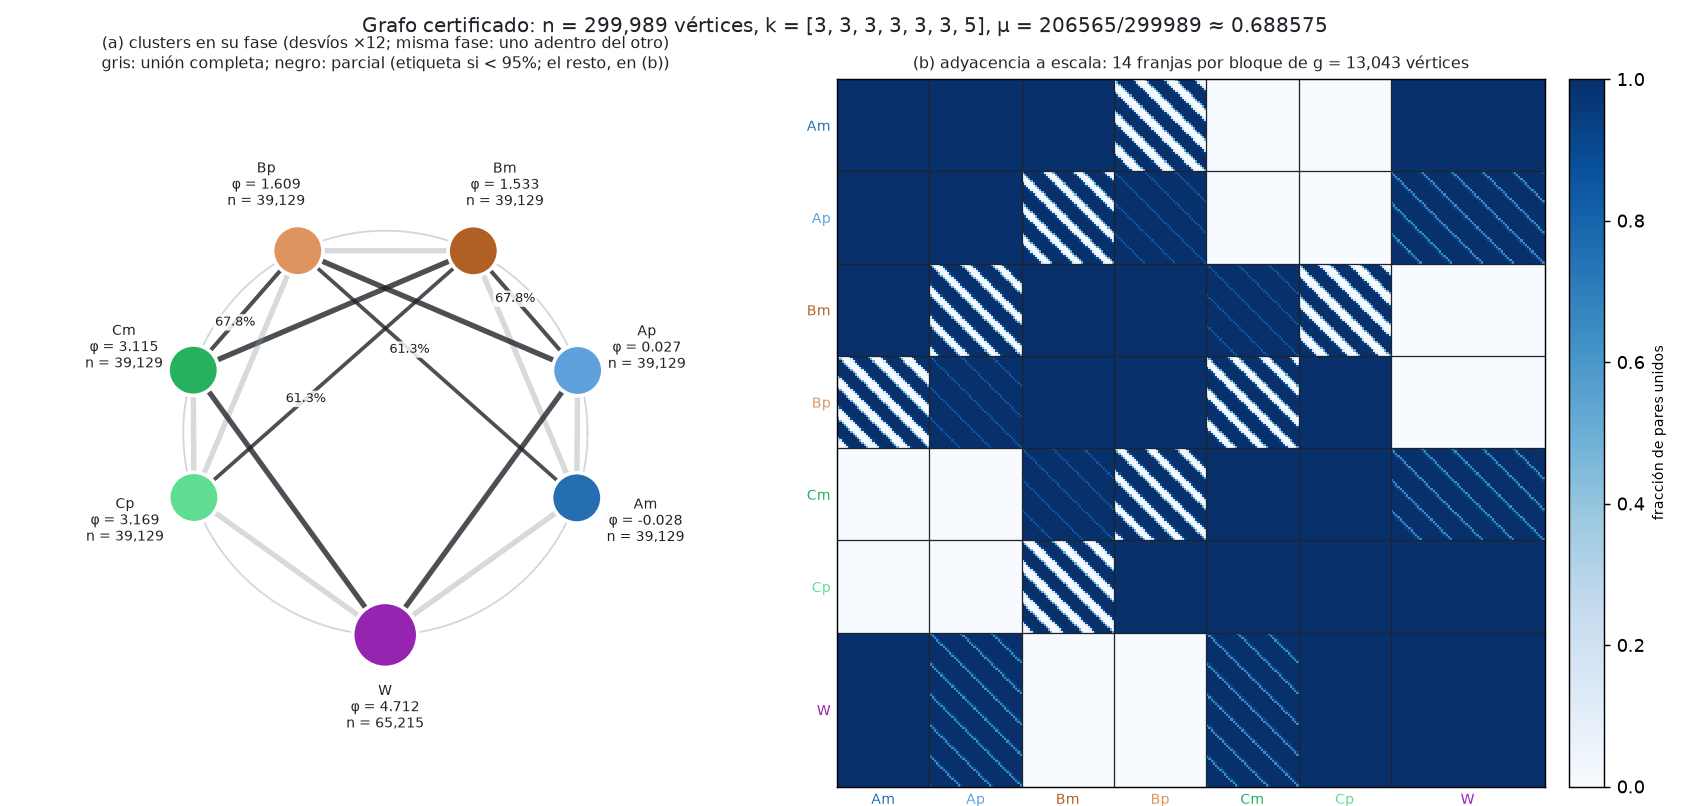

In [15]:
# visualizar_grafo fija el backend Agg de matplotlib: se importa recién acá, en la última figura
sys.path.insert(0, "../scripts")
from visualizar_grafo import dibujar_estructura

archivo = Path("../data/figuras") / f"grafo_simetrico_n{grafo['n']}_estructura.png"
archivo.parent.mkdir(parents=True, exist_ok=True)
dibujar_estructura(descripcion, grafo["certificado"]["mu_exacto"], archivo)
display(Image(filename=str(archivo)))

## 8. Validación: el grafo real, sin la teoría del certificado

El certificado de la sección 5 trabaja con los **datos** del grafo (grados, la plantilla de $7\times7$, los
bloques de Fourier). Si hubiera un error entre los datos y el grafo, por ejemplo al pasar de los cuatro
enteros a las tablas de transporte, el certificado no lo vería. Por eso lo chequeamos de dos maneras
independientes, sobre el grafo guardado en `data/grafo_simetrico_s7.json`:

1. **Validación ciega** (8.1–8.2): a partir de la regla de adyacencia y nada más, contamos los vecinos,
   medimos la velocidad en las fases certificadas y buscamos el menor autovalor del Hessiano con Lanczos.
2. **Espectro completo** (8.3–8.4): Lanczos solo da una cota superior del menor autovalor. Usando la
   estructura circulante, calculamos **todos** los autovalores del Hessiano y los comparamos con las cotas
   del certificado.

Con $n = 299\,989$ las dos cosas corren acá, en CPU, en unos segundos.

### 8.1 Productos implícitos

**El grafo.** El cluster $a$ tiene $k_a$ bloques, y cada bloque es una copia de $\mathbb Z_g$: el vértice
$(a, i, v)$ tiene índice $\text{inicio}_a + i\,g + v$. La regla de adyacencia es:
- **dentro de un cluster:** todos con todos (clique);
- **entre clusters $a < b$:** $(a, i, v) \sim (b, j, v + s \bmod g)$ para $s \in \{0, \dots, t_{ij} - 1\}$,
  con la tabla de transporte $t$ guardada en el JSON.

Armar la matriz es imposible: tiene $\sim 6\cdot10^{10}$ entradas no nulas. Solo usamos productos
matriz-vector, que salen de la regla.

**$W y$ implícito:**
- **dentro de un cluster:** $(Wy)_u = \sum_{v \in a} y_v - y_u$;
- **entre clusters:** $(a, i, v)$ recibe $\sum_j \sum_{s < t_{ij}} y_{(b,j,v+s)}$, una suma sobre una
  ventana cíclica, y $(b, j, w)$ recibe la ventana hacia atrás $\sum_i \sum_{s < t_{ij}} y_{(a,i,w-s)}$.

Con la suma prefija $S$ de $[y, y]$ (cada bloque repetido dos veces, para no preocuparse por el
"mod $g$"), la ventana hacia adelante es $S[v + t] - S[v]$: cada una cuesta $O(1)$ y un producto cuesta
$O(nk)$. Dos detalles:
- **precisión:** cada bloque se centra por su media antes de la suma prefija (la media se suma después,
  $t$ veces); sin eso, las sumas prefijas largas pierden dígitos;
- **máscaras:** las tablas solo tienen dos valores ($\text{base}$ y $\text{base}+1$). Para cada valor $t$
  se guarda la matriz 0/1 $M_t$ ($k_a \times k_b$) de los pares $(i, j)$ que lo tienen, y $M_t$ reparte
  entre los bloques de $a$ las ventanas de todos los bloques de $b$, calculadas de una vez.

**$H x$ implícito.** Con $\cos(\theta_u - \theta_v) = \cos\theta_u\cos\theta_v + \sin\theta_u\sin\theta_v$:
$$Hx = h \circ x - \cos\theta \circ W(\cos\theta \circ x) - \sin\theta \circ W(\sin\theta \circ x),
\qquad h = \cos\theta \circ W\cos\theta + \sin\theta \circ W\sin\theta.$$
No usa que las fases sean constantes por cluster.

**El código** (copiado de `src/validacion.py`). En `src/` son métodos de la clase `GrafoImplicito`, que
guarda $k$, $g$, las máscaras, $\cos\theta$, $\sin\theta$ y $h$, y que trabaja con numpy o con torch a través
de un objeto `arreglos`. Acá están copiados como funciones que reciben ese objeto (`grafo`);
`grafo.por_cluster(y)` parte $y$ en una matriz $k_a \times g$ por cluster. Cada copia se compara con el
original.

In [ ]:
guardado_simetrico = cargar_json("grafo_simetrico_s7.json")
descripcion = guardado_simetrico["grafo"]
certificado = guardado_simetrico["certificado"]
implicito = GrafoImplicito(descripcion, Arreglos())


def producto_adyacencia(grafo, y):
    # W·y. Las ventanas cíclicas salen de sumas prefijas de y centrado por bloque (más preciso).
    g = grafo.g
    salida = grafo.arreglos.ceros(grafo.n)
    partes = grafo.por_cluster(y)
    partes_salida = grafo.por_cluster(salida)
    medias = []
    prefijas = []
    for a, Y in enumerate(partes):
        partes_salida[a] += Y.sum() - Y
        media = grafo.arreglos.media_filas(Y)
        medias.append(media)
        prefijas.append(grafo.arreglos.suma_prefija_doble(Y - media))
    for (a, b), mascaras in grafo.mascaras.items():
        for t, M in mascaras:
            # (a, i, v) recibe Σ_{s<t} y_(b, j, v+s);  (b, j, w) recibe Σ_{s<t} y_(a, i, w−s)
            adelante = prefijas[b][:, t: t + g] - prefijas[b][:, :g] + t * medias[b]
            atras = prefijas[a][:, g + 1: 2 * g + 1] - prefijas[a][:, g + 1 - t: 2 * g + 1 - t] + t * medias[a]
            partes_salida[a] += M @ adelante
            partes_salida[b] += M.T @ atras
    return salida


def producto_hessiano(grafo, x):
    # H·x con H = diag(Σ_v W_uv cos(θ_u − θ_v)) − [W_uv cos(θ_u − θ_v)].
    cruzado = (grafo.coseno * producto_adyacencia(grafo, grafo.coseno * x)
               + grafo.seno * producto_adyacencia(grafo, grafo.seno * x))
    return grafo.diagonal * x - cruzado


x_prueba = np.random.default_rng(1).standard_normal(implicito.n)
assert np.allclose(producto_adyacencia(implicito, x_prueba), implicito.producto_adyacencia(x_prueba))
assert np.allclose(producto_hessiano(implicito, x_prueba), implicito.producto_hessiano(x_prueba))
inicio = time.time()
producto_hessiano(implicito, x_prueba)
print(f"n = {implicito.n:,},\n k = {implicito.k},\n g = {implicito.g:,}: un producto H·x tarda {time.time() - inicio:.2f} s")

n = 299,989, k = [3, 3, 3, 3, 3, 3, 5], g = 13,043: un producto H·x tarda 0.03 s


**Los chequeos.** Con esos productos:
1. **Grados:** $W\mathbf 1_b$ cuenta los vecinos de cada vértice en el cluster $b$. El mínimo y el máximo
   en cada cluster $a$ tienen que ser exactamente $d_{ab}$ (son enteros, así que en float64 es exacto).
2. **Velocidad:** $\dot\theta = \cos\theta \circ W\sin\theta - \sin\theta \circ W\cos\theta$ en las fases
   certificadas. Tiene que ser error de redondeo.
3. **Modos de cluster:** $Q_{ab} = \mathbf 1_a^\top H \mathbf 1_b/\sqrt{n_a n_b}$ con $H$ implícito, contra la
   fórmula de los grados
   $Q_{ab} = -\sqrt{n_a/n_b}\,d_{ab}\cos_{ab}$, $Q_{aa} = \sum_{c \ne a} d_{ac}\cos_{ac}$.
   Si los grados son exactos, los vectores constantes por cluster forman un subespacio invariante de $H$,
   y sus autovalores son los de $Q$ (uno es la rotación, $\approx 0$).

**El código** (copiado de `src/validacion.py`):

In [4]:
def grados_medidos(grafo):
    # Matriz (m × m) con [min, max] de los vecinos que tiene un vértice de a en b, contados con W·1_b.
    m = len(grafo.k)
    minimos = np.zeros((m, m), dtype=np.int64)
    maximos = np.zeros((m, m), dtype=np.int64)
    for b in range(m):
        cuenta = grafo.arreglos.a_numpy(producto_adyacencia(grafo, grafo.indicadora(b)))
        for a in range(m):
            tramo = cuenta[grafo.inicios[a]: grafo.inicios[a] + grafo.k[a] * grafo.g]
            minimos[a, b] = int(np.rint(tramo.min()))
            maximos[a, b] = int(np.rint(tramo.max()))
    return minimos, maximos


def cociente_implicito(grafo):
    # Q_ab = 1_aᵀ H 1_b / √(n_a n_b), calculada con el producto implícito.
    m = len(grafo.k)
    Q = np.zeros((m, m))
    tamanos = [ka * grafo.g for ka in grafo.k]
    for b in range(m):
        columna = grafo.arreglos.a_numpy(producto_hessiano(grafo, grafo.indicadora(b)))
        for a in range(m):
            tramo = columna[grafo.inicios[a]: grafo.inicios[a] + tamanos[a]]
            Q[a, b] = tramo.sum() / np.sqrt(tamanos[a] * tamanos[b])
    return Q


def cociente_formula(descripcion):
    # La misma Q con la fórmula de los grados: Q_ab = −√(n_a/n_b) d_ab cos_ab, Q_aa = Σ_{c≠a} d_ac cos_ac.
    k = descripcion["k"]
    g = descripcion["g"]
    d = np.array(descripcion["grados"], dtype=float)
    fases = np.array([float(p) for p in descripcion["fases"]])
    coseno = np.cos(fases[:, None] - fases[None, :])
    tamanos = np.array(k, dtype=float) * g
    Q = -np.sqrt(tamanos[:, None] / tamanos[None, :]) * d * coseno
    for a in range(len(k)):
        Q[a, a] = sum(d[a, c] * coseno[a, c] for c in range(len(k)) if c != a)
    return Q


assert np.allclose(cociente_formula(descripcion), validacion.cociente_formula(descripcion))

4. **El resto de los modos:** el menor autovalor de $H$ en el complemento de los modos de cluster.
5. **Todo junto:** el menor autovalor de $H$ en $\mathbf 1^\perp$ (sin la rotación), desde un vector al azar
   y sin separar nada. Tiene que dar el menor autovalor de $Q$ que no es la rotación.

**Lanczos** encuentra el menor autovalor usando solo productos $Hx$. Genera una base ortonormal
$q_1, q_2, \dots$ del espacio de Krylov $\{x, Hx, H^2x, \dots\}$ con la recurrencia de tres términos
$$\beta_k q_{k+1} = Hq_k - \alpha_k q_k - \beta_{k-1}q_{k-1}.$$
- Los autovalores de la tridiagonal $T_k = \mathrm{tridiag}(\beta, \alpha, \beta)$ (los **valores de
  Ritz**) aproximan los extremos del espectro.
- Si $s$ es el autovector de $T_k$ del menor valor de Ritz $\vartheta$, el residuo de su vector de Ritz
  es $\|Hy - \vartheta y\| = \beta_k |s_k|$, y se calcula sin armar $y$.
- **Proyección:** para buscar en un subespacio se proyecta después de cada producto: restar la media de
  cada cluster (paso 4) o la media global (paso 5).
- **Detalle numérico:** el resto del espectro es muy degenerado y $\beta$ cae a $\sim10^{-10}$ en pocos
  pasos. Entonces $w/\beta$ amplifica el redondeo en las direcciones proyectadas afuera y aparece un valor
  de Ritz espurio $\approx 0$. Se evita reproyectando $w$ antes de normalizarlo.

**El código** (copiado de `src/validacion.py`):

In [5]:
def extremos_ritz(alfas, betas):
    # (menor valor de Ritz, último componente de su vector, mayor valor de Ritz) de la tridiagonal.
    if len(alfas) == 1:
        return alfas[0], 1.0, alfas[0]
    menor, vector = eigh_tridiagonal(alfas, betas[:-1], select="i", select_range=(0, 0))
    mayor = eigh_tridiagonal(alfas, betas[:-1], eigvals_only=True, select="i",
                             select_range=(len(alfas) - 1, len(alfas) - 1))
    return float(menor[0]), float(vector[-1, 0]), float(mayor[0])


def lanczos(aplicar, proyectar, inicial, arreglos, iteraciones, cada=25, tolerancia=1e-6):
    # Lanczos sin reortogonalizar para el menor autovalor de un operador simétrico, con proyección.
    q = proyectar(inicial)
    q = q / arreglos.norma(q)
    q_anterior = None
    beta = 0.0
    alfas = []
    betas = []
    historial = []
    escala = 0.0
    for paso in range(1, iteraciones + 1):
        w = proyectar(aplicar(q))
        alfa = arreglos.punto(q, w)
        w = w - alfa * q
        if q_anterior is not None:
            w = w - beta * q_anterior
        # reproyectar: si β es chico, w/β amplifica el redondeo en las direcciones proyectadas
        w = proyectar(w)
        beta = arreglos.norma(w)
        alfas.append(alfa)
        betas.append(beta)
        escala = max(escala, abs(alfa))
        final = paso == iteraciones or beta <= 1e-12 * escala
        if paso % cada == 0 or final:
            menor, ultimo, mayor = extremos_ritz(np.array(alfas), np.array(betas))
            historial.append({"paso": paso, "menor": menor, "residuo": beta * abs(ultimo), "mayor": mayor})
            if historial[-1]["residuo"] <= tolerancia * abs(menor) or final:
                break
        q_anterior = q
        q = w / beta
    return {"menor": historial[-1]["menor"], "residuo": historial[-1]["residuo"],
            "mayor": historial[-1]["mayor"], "pasos": historial[-1]["paso"], "historial": historial}

### 8.2 Validación ciega del grafo de 299 989 vértices

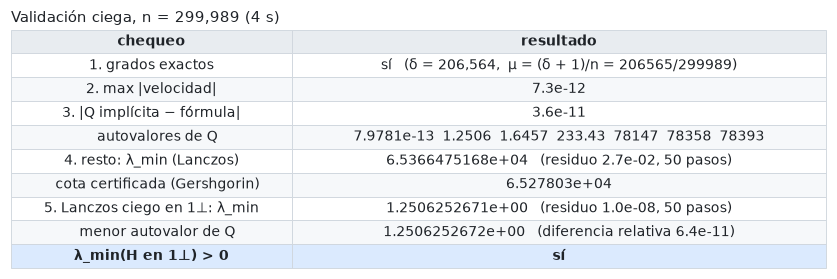

In [6]:
inicio_validacion = time.time()
minimos, maximos = grados_medidos(implicito)
esperados = np.array(descripcion["grados"])
grados_ok = bool((minimos == esperados).all() and (maximos == esperados).all())
grado_min = int(esperados.sum(axis=1).min())
velocidad = np.abs(implicito.coseno * producto_adyacencia(implicito, implicito.seno)
                   - implicito.seno * producto_adyacencia(implicito, implicito.coseno)).max()
Q_implicita = cociente_implicito(implicito)
diferencia_Q = np.abs(Q_implicita - cociente_formula(descripcion)).max()
autovalores_Q = np.linalg.eigvalsh((Q_implicita + Q_implicita.T) / 2)
rotacion = int(np.argmin(np.abs(autovalores_Q)))
menor_cluster = float(np.delete(autovalores_Q, rotacion).min())
cota_fourier = implicito.n * certificado["margen fourier / n (cota inf)"]
cota_cero = implicito.n * certificado["margen cero / n (cota inf)"]
resto = lanczos(lambda v: producto_hessiano(implicito, v), implicito.quitar_medias_cluster,
                implicito.arreglos.aleatorio(implicito.n, 0), implicito.arreglos, iteraciones=30000, cada=50)
completo = lanczos(lambda v: producto_hessiano(implicito, v), implicito.quitar_media,
                   implicito.arreglos.aleatorio(implicito.n, 1), implicito.arreglos, iteraciones=30000, cada=50)
estable = menor_cluster > 0 and resto["menor"] > 0
mostrar_tabla(["chequeo", "resultado"], [
    ["1. grados exactos", f"{si_no(grados_ok)}   (δ = {grado_min:,},  μ = (δ + 1)/n = {certificado['mu_exacto']})"],
    ["2. max |velocidad|", f"{velocidad:.1e}"],
    ["3. |Q implícita − fórmula|", f"{diferencia_Q:.1e}"],
    ["   autovalores de Q", "  ".join(f"{v:.5g}" for v in autovalores_Q)],
    ["4. resto: λ_min (Lanczos)", f"{resto['menor']:.10e}   (residuo {resto['residuo']:.1e}, {resto['pasos']} pasos)"],
    ["   cota certificada (Gershgorin)", f"{min(cota_fourier, cota_cero):.6e}"],
    ["5. Lanczos ciego en 1⊥: λ_min", f"{completo['menor']:.10e}   (residuo {completo['residuo']:.1e}, {completo['pasos']} pasos)"],
    ["   menor autovalor de Q", f"{menor_cluster:.10e}   (diferencia relativa {abs(completo['menor'] - menor_cluster) / menor_cluster:.1e})"],
    ["λ_min(H en 1⊥) > 0", si_no(estable)],
], titulo=f"Validación ciega, n = {implicito.n:,} ({time.time() - inicio_validacion:.0f} s)", resaltar=[8])

**Lectura.**
- **Grados:** exactos, y $\mu = 206565/299989 \approx 0.688575 > 11/16$.
- **Velocidad:** $\sim10^{-11}$, error de redondeo para fuerzas de tamaño $\sim n$: las fases
  certificadas son un equilibrio del grafo real.
- **$Q$:** coincide con la fórmula. Sus autovalores son 0 (la rotación), **1.2506** y 1.6457 (los dos
  modos casi neutros que vienen de C4), 233.4, y tres $\approx 7.8\cdot10^4$.
- **Resto:** $\lambda_{\min} \approx 6.5366\cdot10^4$, apenas arriba de la cota de Gershgorin
  $6.5278\cdot10^4$.
- **Lanczos ciego en $\mathbf 1^\perp$:** desde un vector al azar llega al menor autovalor de $Q$ con una
  diferencia relativa de $\sim10^{-10}$, en 50 pasos. El espectro tiene unos pocos autovalores aislados
  cerca de 0 y una banda lejana, y Lanczos atrapa los aislados enseguida.

Dividido por $n$, $1.2506/n \approx 4.2\cdot10^{-6}$: es el margen de estabilidad de los modos de cluster
del que habla la sección 4, el que limita qué tan chico puede ser $n$.

<table>
<tr><th align="left">▶ Cómo correr <code>scripts/validar_grafo.py</code> (desde la raíz del repo)</th></tr>
<tr><td align="left"><b>Máquina:</b> CPU local (cualquiera; no hace falta torch)<br><b>Tiempo:</b> 0.03 s por producto H·x, 4 s en total<br><b>Salida:</b> <code>data/validacion_s7_n299989.json</code></td></tr>
<tr><td align="left"><pre># los cinco chequeos de arriba, sobre el grafo simétrico
python scripts/validar_grafo.py --archivo grafo_simetrico_s7.json --dispositivo numpy --completo</pre></td></tr>
</table>

El script hace lo mismo que las celdas de arriba (son las mismas funciones) y guarda el resultado en un
JSON. Sin `--archivo` valida el grafo general de $3\cdot10^7$ vértices.

### 8.3 El espectro completo por bloques de Fourier

**Lo que Lanczos no puede dar.** Cada valor de Ritz es **mayor o igual** que el verdadero menor autovalor
(entrelazamiento de Cauchy: $T_k$ es la compresión de $H$ a un subespacio). El residuo garantiza que hay
un autovalor cerca de $\vartheta$, pero no descarta uno más chico que el vector inicial no "vio". Por eso,
en el paso 4, "Lanczos ≥ cota" es **consistente** con el certificado pero no lo prueba: solo detectaría un
error si diera menos que la cota. La precisión de float64 no es el problema (el error es
$\sim10^{-16}\|H\| \approx 10^{-11}$); el problema es que la cota es de un solo lado.

**La estructura circulante.** Correr $v \to v + 1$ en todos los bloques a la vez es un automorfismo del
grafo y deja fijas las fases, así que conmuta con $H$. Con la transformada de Fourier en cada bloque,
$H$ se parte en $g$ matrices hermíticas $H_m$ de $K \times K$ ($K = \sum_a k_a = 23$), una por frecuencia
$m = 0, \dots, g - 1$, y el espectro de $H$ es la unión de sus espectros. Si $\cos_{ab} = \cos(\varphi_a - \varphi_b)$:

| entrada de $H_m$ | valor |
|---|---|
| $(a,i), (a,i)$ | $\sum_b d_{ab}\cos_{ab} - (g\,[m = 0] - 1)$ |
| $(a,i), (a,j)$, $i \ne j$ | $-g\,[m = 0]$ |
| $(a,i), (b,j)$, $a < b$ | $-\cos_{ab}\,\hat N_{ij}(m)$, y su conjugado en $(b,j),(a,i)$ |

con $\hat N_{ij}(m) = \sum_{s < t_{ij}} e^{2\pi i m s/g}$ la transformada del intervalo de la tabla. El clique
de un bloque ($\mathbb Z_g$ menos el propio vértice) tiene transformada $g[m=0] - 1$, y el de dos bloques
distintos del mismo cluster, $g[m=0]$.

**Tres detalles:**
- **Fórmula cerrada:** $\hat N(m) = e^{i\pi m(t-1)/g}\,\sin(\pi m t/g)/\sin(\pi m/g)$ (y $t$ si $m = 0$), la
  suma geométrica. Los productos $m\cdot t$ se reducen módulo $2g$ en enteros antes de multiplicar por
  $\pi/g$, así los ángulos no pierden precisión.
- **Mitad de las frecuencias:** $\hat N(g - m) = \overline{\hat N(m)}$, así que $H_{g-m} = \overline{H_m}$ tiene
  los mismos autovalores. Alcanza con $m = 0, \dots, \lfloor g/2 \rfloor$.
- **$m = 0$ contiene los modos de cluster:** son los vectores constantes en los bloques de cada cluster
  (base $C$ de $K \times 7$). $C^\top H_0 C$ da los 7 autovalores de $Q$, y el complemento ($K - 7 = 16$
  direcciones: diferencias entre bloques de un mismo cluster) da el resto de $m = 0$. El acople
  $C^\top H_0 C^\perp$ tiene que ser 0.

Son $6\,522$ matrices de $23\times23$: menos de un segundo. Para el grafo de $3\cdot10^7$ vértices son
$652\,175$, unos 30 s en CPU.

**Antes de usarlo, se valida:** el producto $Hx$ por bloques (FFT de cada bloque, $H_m$ en cada frecuencia,
FFT inversa) se compara con el producto implícito de 8.1, que solo usa la regla de adyacencia.

**El código** (copiado de `src/espectro.py`, sin el aviso de progreso):

In [7]:
def inicios_bloques(k):
    # Índice del primer bloque de cada cluster dentro de los K bloques.
    return np.cumsum([0] + list(k[:-1]))


def transformada_intervalos(tabla, g, frecuencias):
    # N̂_ij(m) = Σ_{s<t_ij} e^{2πi m s/g} con forma (M, k_a, k_b), por la fórmula de la suma geométrica.
    t = np.asarray(tabla, dtype=np.int64)[None, :, :]
    m = np.asarray(frecuencias, dtype=np.int64)[:, None, None]
    fase = np.pi * ((m * (t - 1)) % (2 * g)) / g
    numerador = np.sin(np.pi * ((m * t) % (2 * g)) / g)
    denominador = np.sin(np.pi * m / g)
    cociente = np.divide(numerador, denominador, out=np.zeros(numerador.shape), where=denominador != 0)
    return np.where(m == 0, t.astype(float), np.exp(1j * fase) * cociente)


def bloques_fourier(descripcion, frecuencias):
    # Bloques H_m (M × K × K, hermíticos) del Hessiano, para las frecuencias dadas.
    k = list(descripcion["k"])
    g = int(descripcion["g"])
    d = np.array(descripcion["grados"], dtype=float)
    fases = np.array([float(p) for p in descripcion["fases"]])
    coseno = np.cos(fases[:, None] - fases[None, :])
    frecuencias = np.asarray(frecuencias, dtype=np.int64)
    inicios = inicios_bloques(k)
    K = sum(k)
    H = np.zeros((len(frecuencias), K, K), dtype=complex)
    clique = np.where(frecuencias == 0, g, 0).astype(float)
    for a, ka in enumerate(k):
        indices = np.arange(inicios[a], inicios[a] + ka)
        H[:, indices[:, None], indices[None, :]] = -clique[:, None, None] * np.ones((ka, ka))
        diagonal = float((d[a] * coseno[a]).sum())
        H[:, indices, indices] = diagonal - (clique[:, None] - 1)
    for clave, tabla in descripcion["tablas"].items():
        a, b = (int(c) for c in clave.split(","))
        N = transformada_intervalos(tabla, g, frecuencias)
        filas = slice(inicios[a], inicios[a] + k[a])
        columnas = slice(inicios[b], inicios[b] + k[b])
        H[:, filas, columnas] = -coseno[a, b] * N
        H[:, columnas, filas] = -coseno[a, b] * np.conj(N).transpose(0, 2, 1)
    return H


def producto_fourier(descripcion, x, lote=4096):
    # H·x por bloques: FFT en cada bloque Z_g, H_m en cada frecuencia y FFT inversa.
    K = sum(descripcion["k"])
    g = int(descripcion["g"])
    X = np.fft.fft(np.asarray(x, dtype=float).reshape(K, g), axis=1)
    Y = np.empty_like(X)
    for inicio in range(0, g, lote):
        m = np.arange(inicio, min(inicio + lote, g))
        Y[:, m] = np.einsum("mij,jm->im", bloques_fourier(descripcion, m), X[:, m])
    return np.fft.ifft(Y, axis=1).real.reshape(-1)


def base_cluster(k):
    # Matriz K × len(k): columna a = indicadora de los bloques del cluster a, normalizada.
    C = np.zeros((sum(k), len(k)))
    inicios = inicios_bloques(k)
    for a, ka in enumerate(k):
        C[inicios[a]: inicios[a] + ka, a] = 1 / np.sqrt(ka)
    return C


def espectro_fourier(descripcion, lote=4096):
    # Todos los autovalores de H: modos de cluster, resto de m = 0 y el menor de cada m = 1, …, ⌊g/2⌋.
    k = list(descripcion["k"])
    g = int(descripcion["g"])
    H0 = bloques_fourier(descripcion, [0])[0].real
    C = base_cluster(k)
    completa, _ = np.linalg.qr(C, mode="complete")
    resto = completa[:, len(k):]
    cluster = np.linalg.eigvalsh(C.T @ H0 @ C)
    cero = np.linalg.eigvalsh(resto.T @ H0 @ resto)
    frecuencias = np.arange(1, g // 2 + 1)
    minimos = np.empty(len(frecuencias))
    maximo = max(cluster.max(), cero.max())
    for inicio in range(0, len(frecuencias), lote):
        tramo = slice(inicio, min(inicio + lote, len(frecuencias)))
        valores = np.linalg.eigvalsh(bloques_fourier(descripcion, frecuencias[tramo]))
        minimos[tramo] = valores[:, 0]
        maximo = max(maximo, float(valores[:, -1].max()))
    return {
        "cluster": cluster, "cero": cero, "frecuencias": frecuencias, "minimos": minimos,
        "acople": float(np.abs(C.T @ H0 @ resto).max()), "maximo": float(maximo),
    }


frecuencias_prueba = [0, 1, 2, implicito.g // 3, implicito.g // 2]
assert np.allclose(bloques_fourier(descripcion, frecuencias_prueba),
                   espectro.bloques_fourier(descripcion, frecuencias_prueba))
for m in frecuencias_prueba:
    t = descripcion["tablas"]["0,3"][0][0]
    directa = np.exp(2j * np.pi * m * np.arange(t) / implicito.g).sum()
    assert abs(transformada_intervalos([[t]], implicito.g, [m])[0, 0, 0] - directa) < 1e-8 * t

### 8.4 El espectro del grafo simétrico

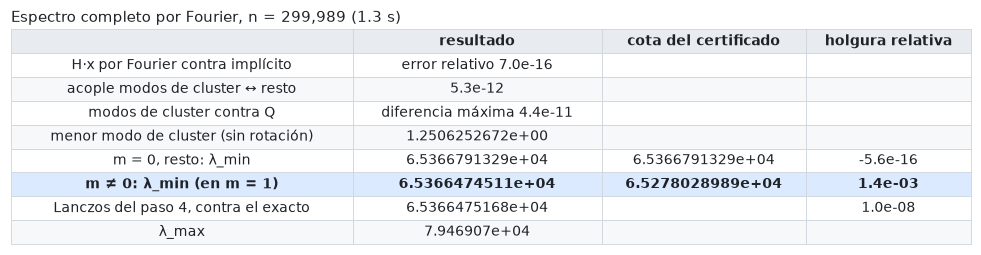

In [8]:
inicio_espectro = time.time()
error_producto = 0.0
for semilla in [0, 1]:
    x = np.random.default_rng(semilla).standard_normal(implicito.n)
    directo = producto_hessiano(implicito, x)
    error_producto = max(error_producto, np.linalg.norm(producto_fourier(descripcion, x) - directo) / np.linalg.norm(directo))
completo_fourier = espectro_fourier(descripcion)
segundos_espectro = time.time() - inicio_espectro
menor_cero = float(completo_fourier["cero"].min())
posicion = int(np.argmin(completo_fourier["minimos"]))
menor_m = float(completo_fourier["minimos"][posicion])
diferencia_cluster = np.abs(completo_fourier["cluster"] - np.linalg.eigvalsh(cociente_formula(descripcion))).max()
mostrar_tabla(["", "resultado", "cota del certificado", "holgura relativa"], [
    ["H·x por Fourier contra implícito", f"error relativo {error_producto:.1e}", "", ""],
    ["acople modos de cluster ↔ resto", f"{completo_fourier['acople']:.1e}", "", ""],
    ["modos de cluster contra Q", f"diferencia máxima {diferencia_cluster:.1e}", "", ""],
    ["menor modo de cluster (sin rotación)", f"{np.sort(completo_fourier['cluster'])[1]:.10e}", "", ""],
    ["m = 0, resto: λ_min", f"{menor_cero:.10e}", f"{cota_cero:.10e}", f"{menor_cero / cota_cero - 1:.1e}"],
    [f"m ≠ 0: λ_min (en m = {completo_fourier['frecuencias'][posicion]})", f"{menor_m:.10e}", f"{cota_fourier:.10e}",
     f"{menor_m / cota_fourier - 1:.1e}"],
    ["Lanczos del paso 4, contra el exacto", f"{resto['menor']:.10e}", "",
     f"{resto['menor'] / min(menor_m, menor_cero) - 1:.1e}"],
    ["λ_max", f"{completo_fourier['maximo']:.6e}", "", ""],
], titulo=f"Espectro completo por Fourier, n = {implicito.n:,} ({segundos_espectro:.1f} s)", resaltar=[5])

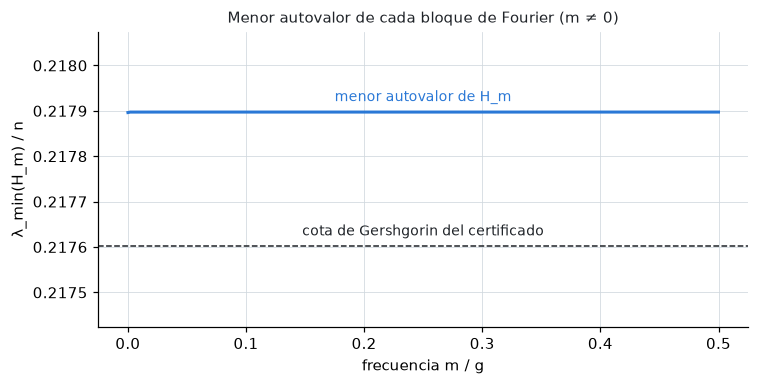

In [9]:
fig, eje = plt.subplots(figsize=(7, 3.6))
m_sobre_g = completo_fourier["frecuencias"] / implicito.g
curva = completo_fourier["minimos"] / implicito.n
cota = cota_fourier / implicito.n
eje.plot(m_sobre_g, curva, color=COLORES[0], lw=2)
eje.axhline(cota, color=TINTA, lw=1, ls="--")
separacion = curva.min() - cota
eje.set_ylim(cota - 0.6 * separacion, curva.max() + 0.6 * separacion)
eje.annotate("menor autovalor de H_m", xy=(0.25, curva.max()), xytext=(0, 5), textcoords="offset points",
             ha="center", va="bottom", fontsize=9, color=COLORES[0])
eje.annotate("cota de Gershgorin del certificado", xy=(0.25, cota), xytext=(0, 5), textcoords="offset points",
             ha="center", va="bottom", fontsize=9, color=TINTA)
eje.set_xlabel("frecuencia m / g")
eje.set_ylabel("λ_min(H_m) / n")
eje.set_title("Menor autovalor de cada bloque de Fourier (m ≠ 0)", fontsize=10, color=TINTA)
eje.grid(color=BORDE, lw=0.5)
for borde in ["top", "right"]:
    eje.spines[borde].set_visible(False)
plt.tight_layout()
plt.show()

**Lectura.**
- **La descomposición es correcta:** el producto por bloques coincide con el implícito a $10^{-15}$, el
  acople de los modos de cluster con el resto es $\sim10^{-12}$ (son invariantes) y los 7 autovalores de
  $C^\top H_0 C$ son los de $Q$.
- **Lanczos daba bien:** su valor del paso 4 queda a $\sim10^{-8}$ relativo del menor autovalor exacto,
  y por encima, como tiene que ser.
- **Gershgorin es casi exacta en $m \ne 0$:** el verdadero mínimo supera la cota en solo 0.14%, y está en
  $m = 1$. La curva es casi plana (la figura): la parte principal de $H_m$ para $m \ne 0$ es la diagonal
  ($\approx 0.22\,n$), y los acoples entre clusters son chicos porque las densidades intermedias están entre
  clusters casi a 90° ($\cos \approx 0$) y las demás son 0 o 1 (sin oscilación en $m$).
- **En $m = 0$ la cota es exacta:** el menor autovalor del resto de $m = 0$ coincide con la cota hasta el
  redondeo de float64 ($10^{-16}$). Lo pone el cluster W: sus tablas con los demás clusters son constantes
  (todas las entradas iguales), así que en las diferencias entre sus bloques no actúa ningún acople y el
  autovalor es exactamente $\sum_b d_{Wb}\cos_{Wb} + 1$, que es lo que calcula la cota.

Ningún autovalor queda debajo de su cota certificada: el certificado es consistente con el espectro
completo, no solo con una cota de un lado.

<table>
<tr><th align="left">▶ Cómo correr <code>scripts/espectro_fourier.py</code> (desde la raíz del repo)</th></tr>
<tr><td align="left"><b>Máquina:</b> CPU local (numpy; no hace falta GPU)<br><b>Tiempo:</b> grafo simétrico: 1 s · grafo general de 3·10⁷ vértices: 126 s, con ~4 GB de RAM<br><b>Salida:</b> <code>data/espectro_s7_n299989.json</code> y <code>data/espectro_s7_n30000004.json</code></td></tr>
<tr><td align="left"><pre># grafo simétrico (el de este notebook)
python scripts/espectro_fourier.py --archivo grafo_simetrico_s7.json

<tr><td align="left"><pre># grafo general de Grafo_explicito_S7.ipynb (n = 30 000 004)
python scripts/espectro_fourier.py</pre></td></tr>
</table>

El script hace lo mismo que 8.4 (con las funciones de `src/espectro.py`, que son las copiadas en 8.3) y
además guarda el menor autovalor de cada $m$, reducido a 2000 puntos. Corrido sobre los dos grafos:

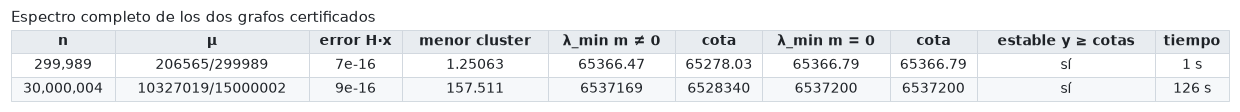

In [10]:
filas = []
for nombre in ["espectro_s7_n299989.json", "espectro_s7_n30000004.json"]:
    e = cargar_json(nombre)
    filas.append([f"{e['n']:,}", e["mu_exacto"], f"{e['error_producto']:.0e}", f"{e['menor_cluster']:.6g}",
                  f"{e['menor_fourier']:.7g}", f"{e['cota_fourier']:.7g}", f"{e['menor_cero']:.7g}",
                  f"{e['cota_cero']:.7g}", si_no(e["estable"] and e["respeta_cotas"]), f"{e['segundos']:.0f} s"])
mostrar_tabla(["n", "μ", "error H·x", "menor cluster", "λ_min m ≠ 0", "cota", "λ_min m = 0", "cota",
               "estable y ≥ cotas", "tiempo"], filas, titulo="Espectro completo de los dos grafos certificados")

**Conclusión de la sección 8.** El grafo de $299\,989$ vértices, armado desde la regla de adyacencia,
tiene los grados del certificado, las fases certificadas son un equilibrio y su Hessiano es definido
positivo en $\mathbf 1^\perp$ con $\lambda_{\min} = 1.2506$. El espectro completo confirma que ningún
autovalor queda debajo de las cotas del certificado. Lo mismo vale para el grafo general de
$3\cdot10^7$ vértices ($\lambda_{\min} = 157.5$).

## 9. Resumen

| | `Grafo_explicito_S7.ipynb` | este notebook |
|---|---|---|
| plantilla | sin simetría, 6 desplazamientos | reflejo, 3 desplazamientos |
| densidades intermedias | 9 pares, 9 valores | 8 pares, **4 valores** |
| enteros libres | 9 | **4** |
| ecuaciones blandas en el redondeo | 3 | **1** |
| método de redondeo | reticulado (Kannan + LLL + Babai) | búsqueda exhaustiva |
| $n$ del grafo certificado | 30 000 004 | **299 989** |
| $\mu$ | 0.688468 | **0.688575** |
| $\lambda_{\min}(H)$ en $\mathbf 1^\perp$ (validación) | 157.5 | 1.2506 |
| espectro completo contra las cotas | sí | sí |

La simetría simplifica todo el camino: la plantilla tiene la mitad de parámetros, el grafo se describe con
cuatro enteros, el redondeo deja de necesitar reticulados, y el grafo certificado es 100 veces más chico y
tiene un $\mu$ un poco mayor. El límite en $n$ ya no lo pone el pliegue sino el margen de estabilidad de
las direcciones antisimétricas (sección 4).

**Validación (sección 8):** el grafo real tiene los grados certificados, las fases son un equilibrio
y el Hessiano es definido positivo; el espectro completo por Fourier respeta las cotas del
certificado en los dos grafos.

**Pendiente:** las simulaciones de la dinámica del notebook original no se repitieron acá. Con
$\lambda_{\min}/n \approx 4\cdot10^{-6}$, la cuenca en las direcciones lentas debería ser tan chica como
allá (sin medir).